# Lab 7: Genetic Algorithms

**26CSCI05I Logic and Artificial Intelligence · Week 9 · Fall 2026/2027**

In Lab 5, hill climbing improved **one** solution step by step and stopped on the first hill it reached. A **genetic algorithm (GA)** keeps a **population** of solutions. In every generation it selects fitter individuals as parents, combines them with **crossover**, changes the children slightly with **mutation**, and forms the next generation. Lecture 7 describes this as *"multiple climbers in parallel"*.

**By the end of this lab you should be able to:**
1. use the terms chromosome, gene, allele, population, fitness, genotype and phenotype, and describe the steps of the Simple GA;
2. trace roulette wheel selection, one-point crossover, bit-flip mutation, cut-and-crossfill and swap mutation by hand;
3. implement these operators and the main loop of a GA, and run it on MAXONE and 8-queens;
4. explain how the same GA is adapted to a new problem by changing the representation, the fitness and the operators.

Each exercise follows the same order: **predict** the result on paper, **trace** it in the interactive activity, complete the **code**, then run the **test** cell.

The tutorial has three exercises. The **Additional Practice** at the end applies the GA to the travelling salesman problem (Exercise 4) and studies its parameters; it is meant for after the lab.


> **Before you start:** complete the cells marked `TODO`. Most of each function is already written; you add a few lines. Until you do, the test cell after it prints `FAIL`, or Python stops with a message that says what is missing. Move on when every line of the test cell says `PASS`.


Run the next cell once. It loads the interactive activities (the landscape, the MAXONE tracer, the operator checker and the GA runs); each activity then appears when you run its `show_activity(...)` cell.


In [36]:
#@title Load the interactive activities (run this cell once)
# This cell only prepares the interactive activities of the lab (the landscape, the MAXONE tracer,
# the operator checker and the GA runs). You do not need to read it: run it once, then run each
# show_activity(...) cell.
import base64, json, uuid, zlib
from IPython.display import HTML

_LAB7 = json.loads(zlib.decompress(base64.b64decode(
    "..."
)).decode())


def show_activity(kind, data_set=None):
    """Display one interactive activity of this lab."""
    box = "lab7-" + uuid.uuid4().hex[:10]
    data = json.dumps(_LAB7["data"].get(data_set))
    key = kind + ("_" + data_set if data_set else "")
    picture = ('<p style="font-size:14px;color:#475569;margin:6px 0 8px"><b>Interactive activity.</b> If you only see this picture: '
               'in the notebook, run the cell "Load the interactive activities" near the top, then run this cell; '
               'in the HTML file, open it in a web browser such as Chrome, Edge or Firefox '
               '(previews inside apps and on phones block interactive content).</p>'
               '<img alt="A picture of the activity" style="max-width:100%;border:1px solid #e2e8f0;border-radius:12px" '
               'src="data:image/jpeg;base64,' + _LAB7["preview"][key] + '">')
    return HTML("<style>" + _LAB7["css"] + "</style>"
                + '<div id="' + box + '">' + picture + "</div>"
                + "<script>" + _LAB7["js"] + 'LAB7.mount("' + box + '", "' + kind + '", ' + data + ");</script>")


print("Interactive activities loaded.")

Interactive activities loaded.


In [37]:
import math
import random
import matplotlib.pyplot as plt


def check(what, got, expected):
    """A tiny test: PASS if got == expected, otherwise FAIL with both values."""
    if got == expected:
        print("PASS ", what)
    else:
        print("FAIL ", what, "-> got", got, "but expected", expected)

---
## 1. Warm-up: one climber or many?

The curve is a **fitness landscape**: each x is a candidate solution and its height is the fitness. The orange point runs hill climbing from Lab 5; the purple points are a GA population of 16. Before you press **Play**, predict where each of them will end. Then try **Run 2**, which starts from a different random population.



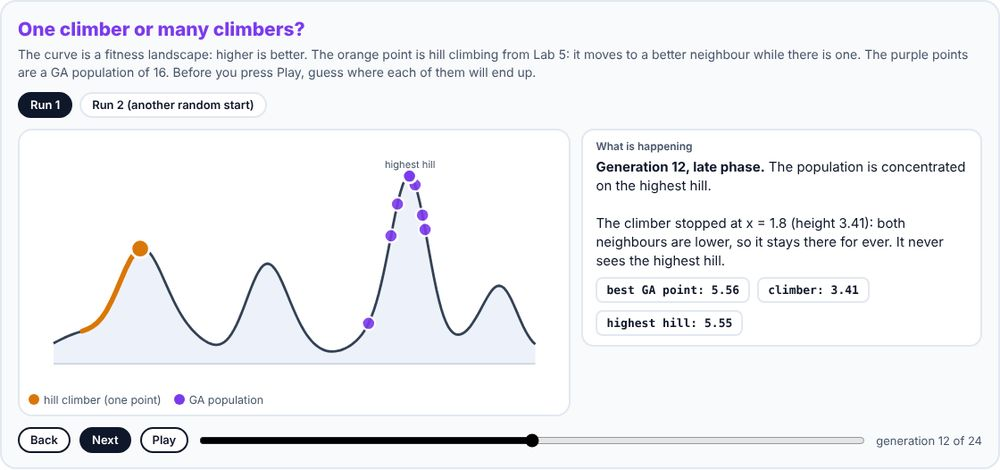

In [38]:
show_activity("climbers", "climbers")

**Question:** why does the hill climber stop on the first hill? What does the population have that a single climber does not? What went wrong in Run 2?


Lecture 7 places GAs (Holland, 1975) among the principal heuristic algorithms, together with simulated annealing (1983) and particle swarm optimisation (1995). All three *"use a combination of randomness and heuristic rules to guide the search"*: *"a genetic algorithm maintains a population of candidate solutions for the problem at hand, and makes it evolve by iteratively applying a set of stochastic operators"*: **selection**, **recombination (crossover)** and **mutation**.


---
## 2. How a genetic algorithm works

> **Key idea.** A GA repeats one loop: **select** fitter parents, **recombine** them, **mutate** the children, **evaluate** them, and **select** the individuals of the next generation.

### 2.1 The words we use


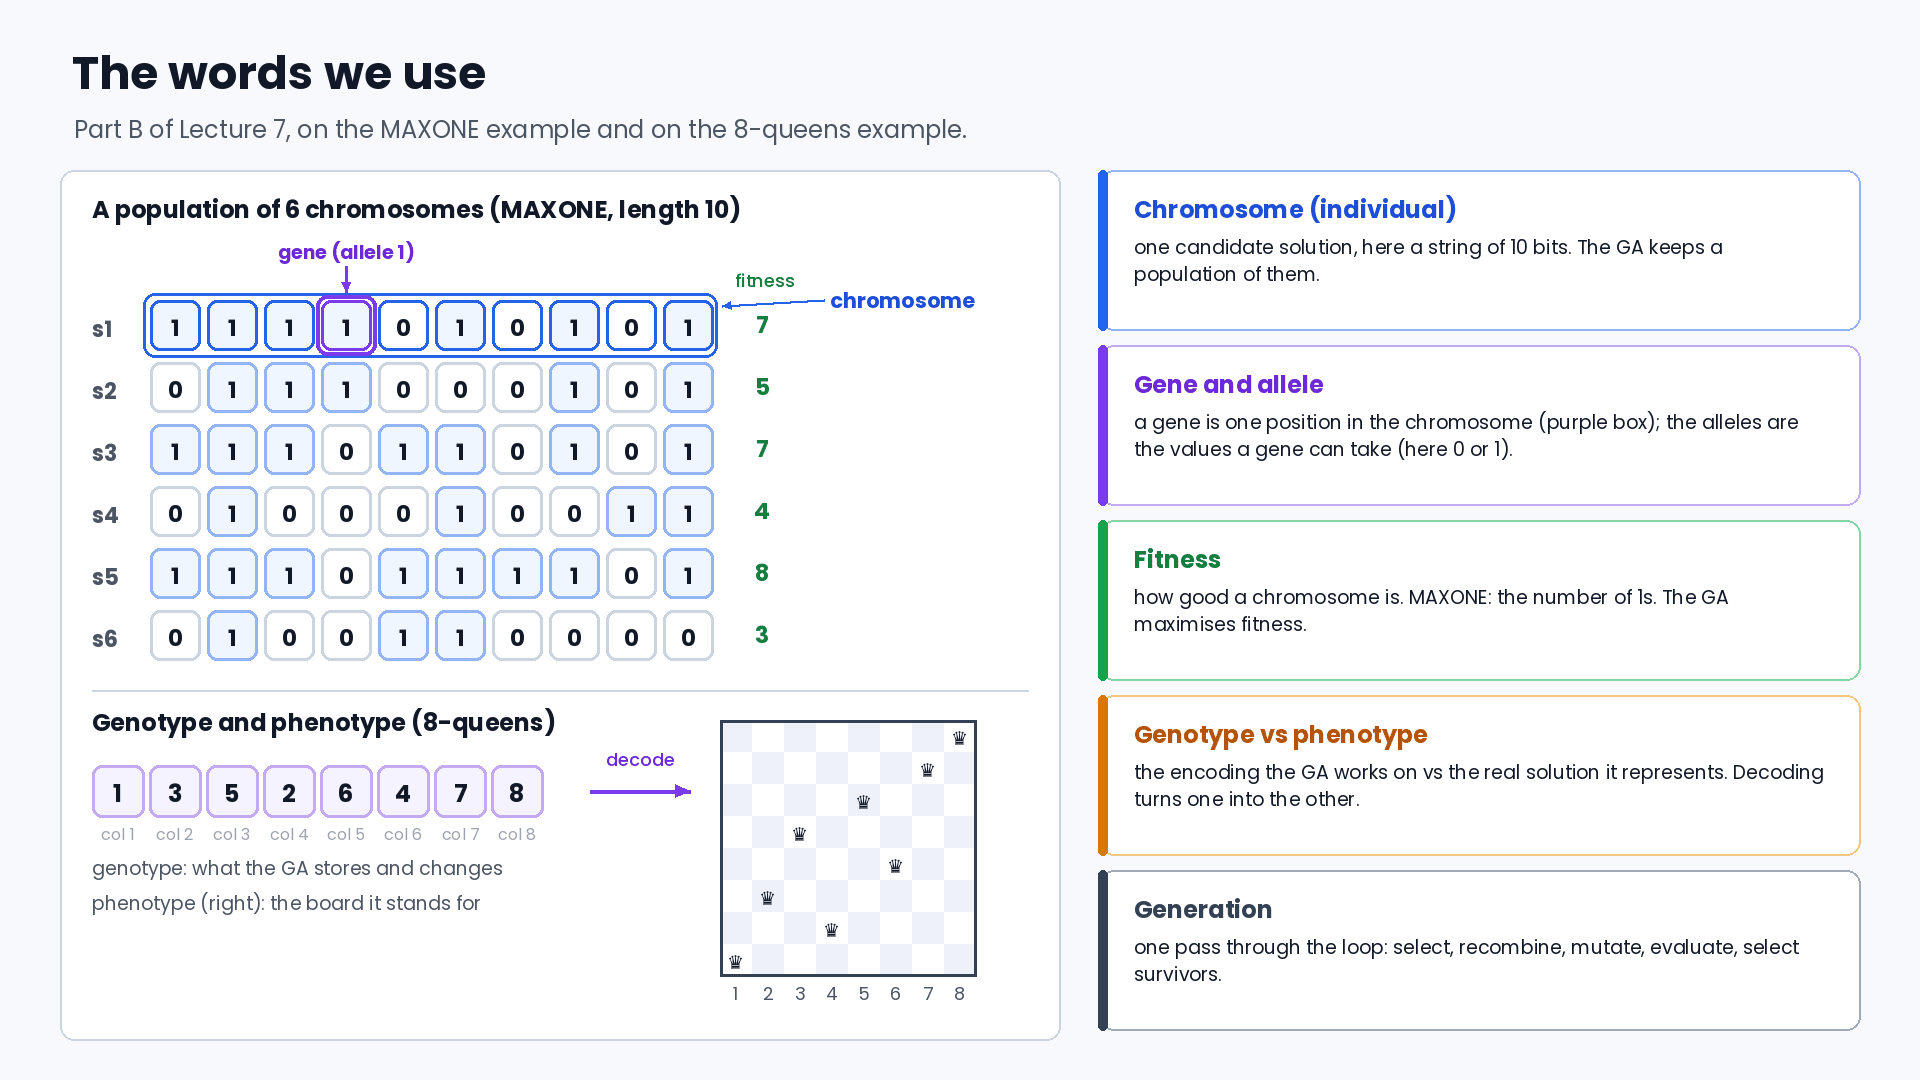


| Genetic algorithm | Nature (the lecture's metaphor) |
|---|---|
| optimisation problem | environment |
| feasible solutions | individuals living in that environment |
| solution quality (fitness function) | how well an individual is adapted to its environment |
| a set of feasible solutions | a population of organisms |
| stochastic operators | selection, recombination and mutation |
| applying the operators repeatedly | evolution of populations to suit their environment |

A GA **maximises** fitness. When the natural measure is a cost (a penalty or a distance), the fitness is defined as an inverse of the cost, as you will see for 8-queens and the TSP.

### 2.2 The evolutionary cycle


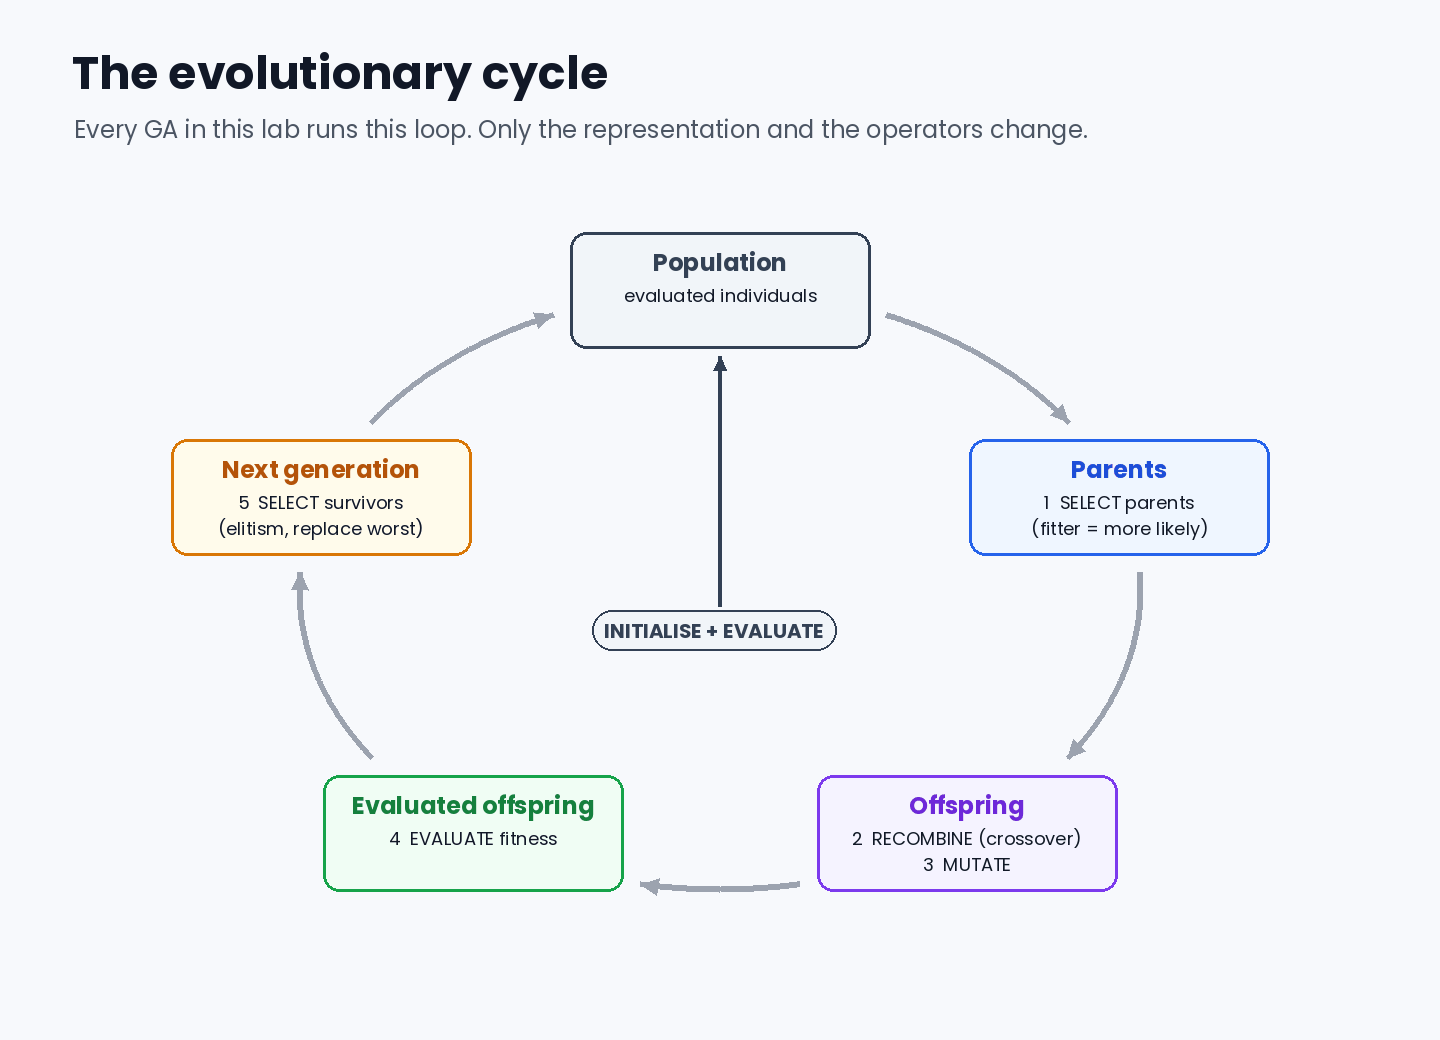


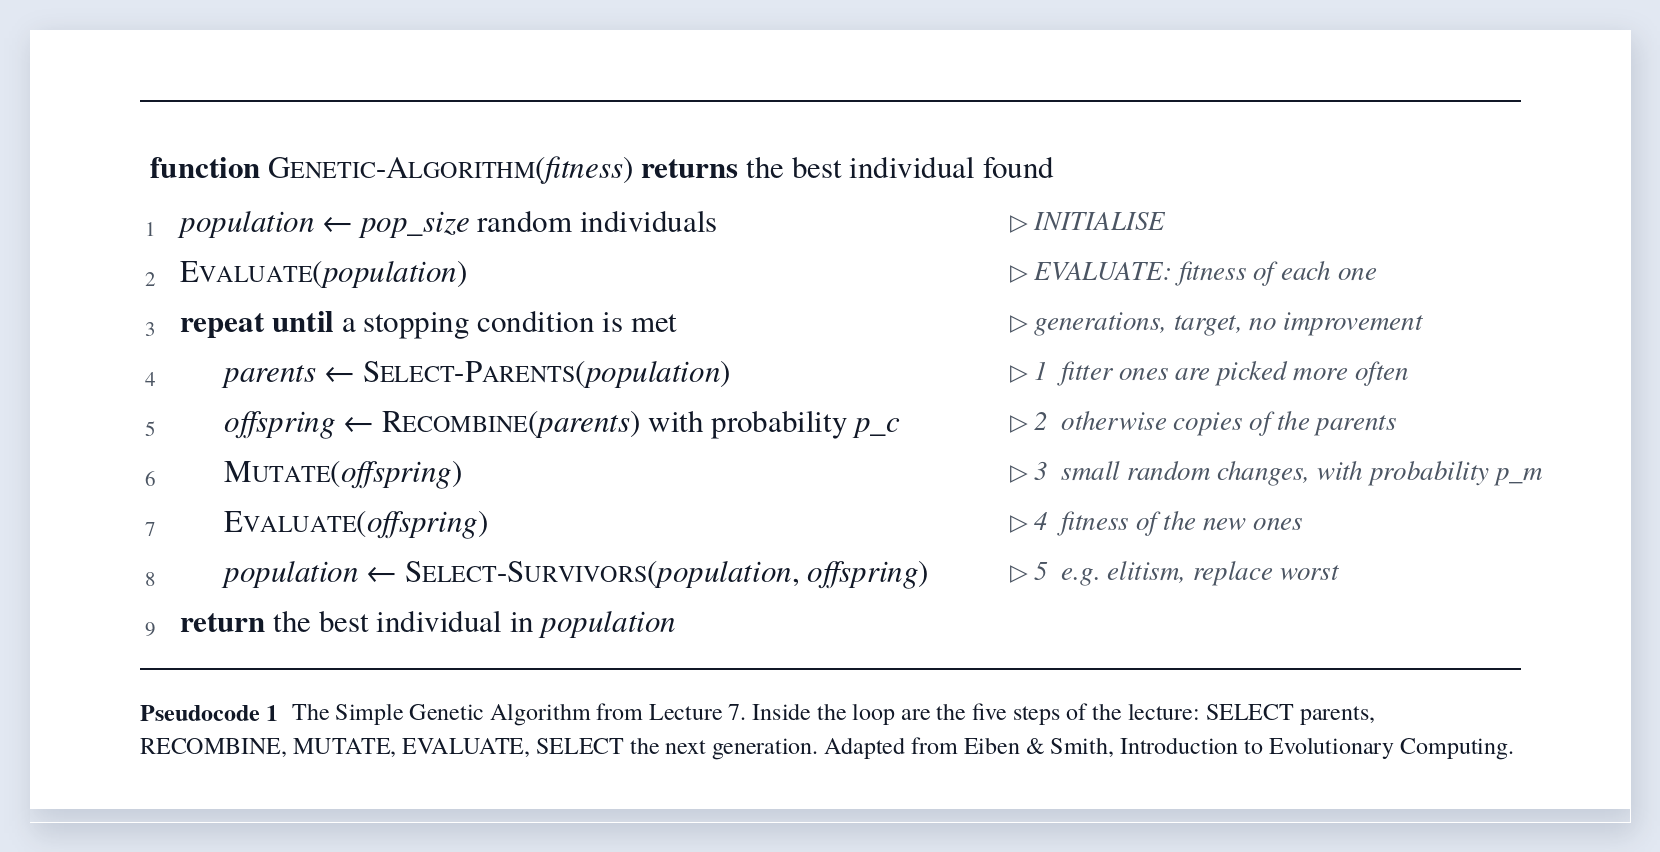


Lecture 7 lists three typical **stopping conditions**: a fixed number of generations or amount of time; a satisfactory solution has been found; or no improvement for a fixed number of generations.

### 2.3 Trace one generation of MAXONE

The lecture's **MAXONE** problem: maximise the number of 1s in a string of 10 bits, with a population of 6. Step through one generation and follow the pseudocode on the left. Note which strings receive two copies, which receive none, and what happens to the total fitness.



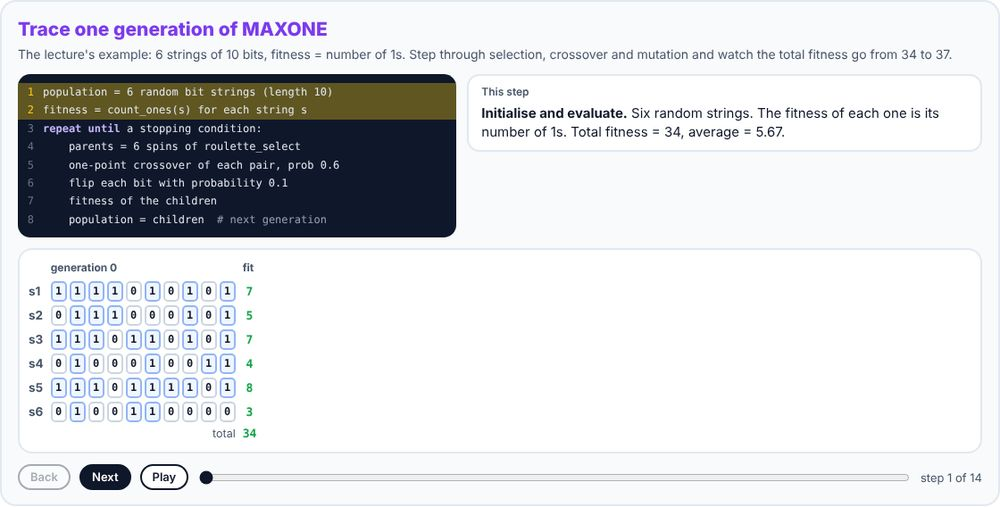

In [39]:
show_activity("maxone", "maxone")

Selection, crossover and mutation are random. The tracer fixes the random numbers (for example the six roulette spins r = 3.1, 15.6, 27.4, 9.8, 21.3, 25.9) so that the result matches the lecture. In the code, every random choice comes from a random number generator `rng`.

### ✏️ Exercise 1: The MAXONE operators

The three operators of the trace: roulette wheel selection, one-point crossover and bit-flip mutation. The lecture also gives two other selection methods; we use the tournament later for the TSP.


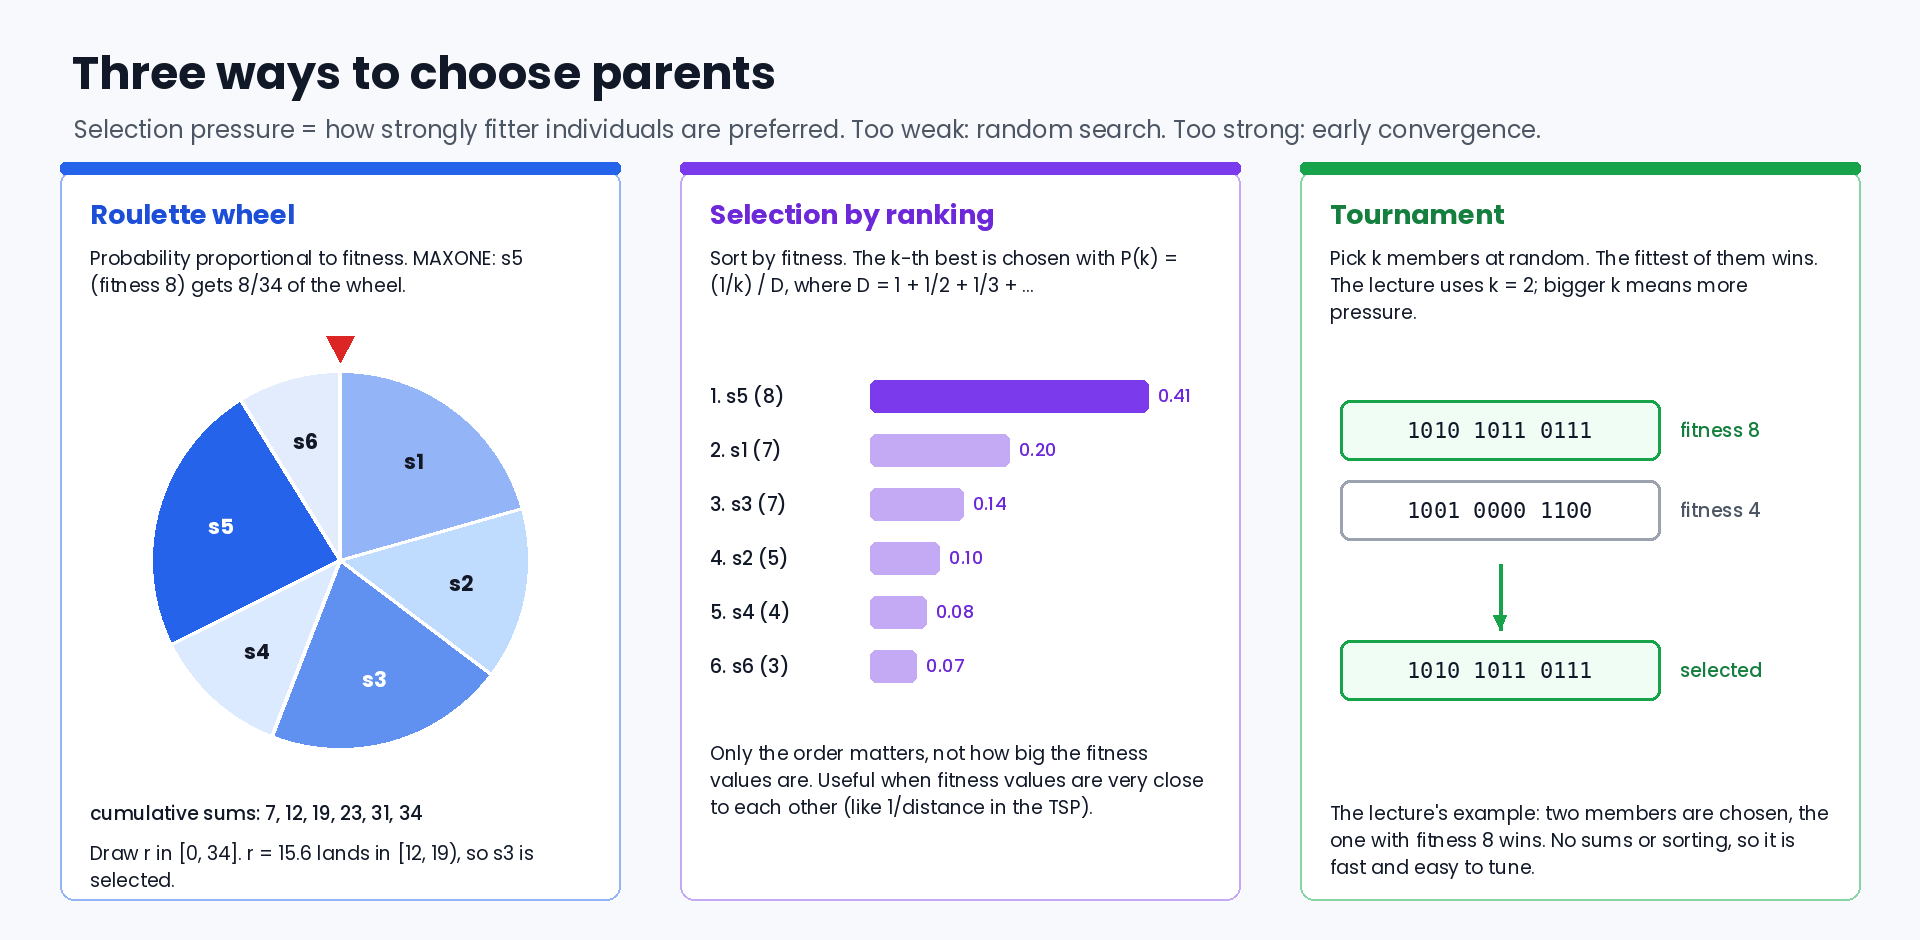


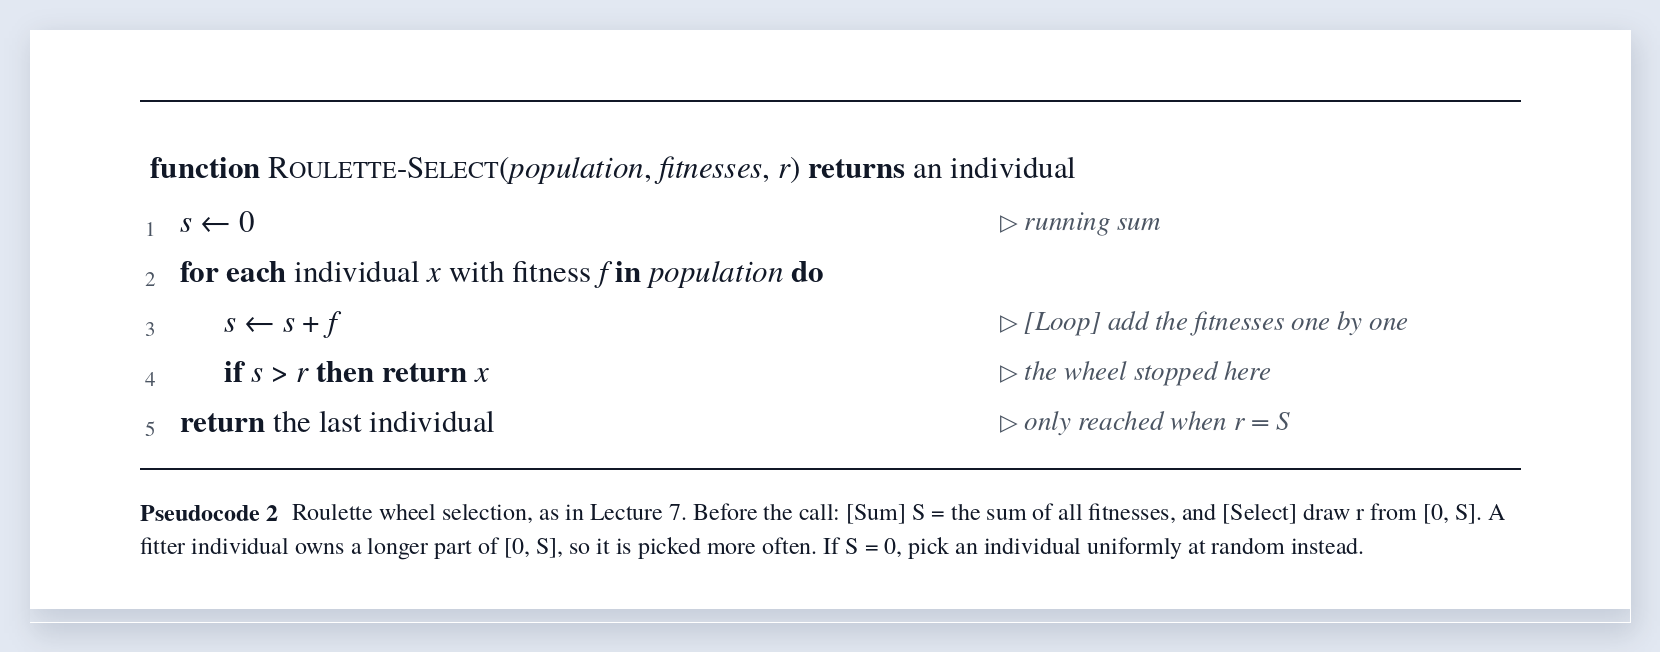


**(a) Predict.** On paper, write your answers in the first code cell:
1. The fitnesses are 7, 5, 7, 4, 8, 3 (S = 34, cumulative sums 7, 12, 19, 23, 31, 34). Which string does `roulette_select` return for **r = 0.5, 7.0, 7.01, 22.9** and **33.9**? Read line 4 of Pseudocode 2 carefully for r = 7.0.
2. The two children of one-point crossover of `"1111010101"` and `"0100110000"` after **4** genes.

**(b) Code.** Complete `roulette_select` (lines 2 to 4 of Pseudocode 2), `one_point_crossover` and `bit_flip_mutation`.

**(c) Test.** Run the test cell. Every line should print `PASS`.


In [40]:
maxone_names = ["s1", "s2", "s3", "s4", "s5", "s6"]
maxone_population = ["1111010101", "0111000101", "1110110101", "0100010011", "1110111101", "0100110000"]

# (a) your predictions
my_picks = None       # TODO: five names for r = 0.5, 7.0, 7.01, 22.9, 33.9, for example ["s1", "s1", "s2", "s3", "s4"]
my_children = None    # TODO: the two children as a pair of strings, ("...", "...")

In [41]:
def count_ones(bits):
    """Fitness for MAXONE: the number of 1s in the bit string."""
    return bits.count("1")


def roulette_select(population, fitnesses, r):
    """Roulette wheel selection for one spin, exactly as in the lecture.

    r is a number in [0, S], where S is the sum of all fitnesses.
    Walk through the population adding fitnesses; when the running sum
    becomes greater than r, return the individual you are at.
    """
    running_sum = 0
    for individual, fit in zip(population, fitnesses):
        # TODO 1: add fit to running_sum
        # TODO 2: if running_sum is now greater than r, return individual
        raise NotImplementedError("complete the loop of roulette_select")
    return population[-1]          # only reached when r == S


def spin_roulette(population, fitnesses, rng):
    """One random spin: draw r from [0, S] and select."""
    S = sum(fitnesses)
    if S == 0:                       # all fitnesses are 0: every individual is equally likely
        return rng.choice(population)
    r = rng.uniform(0, S)
    return roulette_select(population, fitnesses, r)


def one_point_crossover(p1, p2, point):
    """Child = first part of p1 + second part of p2 (cut after `point` genes)."""
    # TODO: return the first `point` genes of p1 followed by the genes of p2 from position `point` on
    raise NotImplementedError("complete one_point_crossover")


def bit_flip_mutation(bits, rate, rng):
    """Bit-flip mutation: each bit flips independently with probability `rate`."""
    out = ""
    for bit in bits:
        # TODO: with probability rate (rng.random() < rate) add the flipped bit to out,
        #       otherwise add the bit unchanged
        raise NotImplementedError("complete bit_flip_mutation")
    return out

In [42]:
maxone_fitness = [count_ones(s) for s in maxone_population]
check("MAXONE fitnesses", maxone_fitness, [7, 5, 7, 4, 8, 3])
spins = [3.1, 15.6, 27.4, 9.8, 21.3, 25.9]
check("the six spins of the tracer", [roulette_select(maxone_names, maxone_fitness, r) for r in spins],
      ["s1", "s3", "s5", "s2", "s4", "s5"])
check("r = 0 selects s1, r = S selects s6", [roulette_select(maxone_names, maxone_fitness, r) for r in (0, 34)], ["s1", "s6"])
check("your roulette predictions", my_picks,
      [roulette_select(maxone_names, maxone_fitness, r) for r in [0.5, 7.0, 7.01, 22.9, 33.9]])
check("lecture: crossover of s1' and s2' after 2 genes",
      (one_point_crossover("1111010101", "1110110101", 2), one_point_crossover("1110110101", "1111010101", 2)),
      ("1110110101", "1111010101"))
check("lecture: crossover of s5' and s6' after 5 genes",
      (one_point_crossover("0100010011", "1110111101", 5), one_point_crossover("1110111101", "0100010011", 5)),
      ("0100011101", "1110110011"))
check("your children", my_children,
      (one_point_crossover("1111010101", "0100110000", 4), one_point_crossover("0100110000", "1111010101", 4)))
rng = random.Random(0)
check("rate 0 changes nothing", bit_flip_mutation("1110110101", 0, rng), "1110110101")
check("rate 1 flips every bit", bit_flip_mutation("1110110101", 1, rng), "0001001010")
flips = sum(a != b for a, b in zip("0" * 10000, bit_flip_mutation("0" * 10000, 0.1, rng)))
check("rate 0.1 flips about 10% of 10,000 bits", 900 < flips < 1100, True)
rng = random.Random(1)
picks = [spin_roulette(maxone_names, maxone_fitness, rng) for _ in range(34000)]
check("s5 is picked about 8/34 of the time", abs(picks.count("s5") / 34000 - 8 / 34) < 0.01, True)
zero = {spin_roulette(maxone_names, [0] * 6, rng) for _ in range(200)}
check("all fitnesses 0: every string can still be picked", len(zero), 6)

PASS  MAXONE fitnesses


NotImplementedError: complete the loop of roulette_select

### ✏️ Exercise 2: The GA loop

`genetic_algorithm` is Pseudocode 1 in Python. It knows nothing about bits, queens or cities: the problem is passed in as functions.

| Argument | What it does | MAXONE |
|---|---|---|
| `fitness(individual)` | returns the fitness (bigger is better) | `count_ones` |
| `new_individual(rng)` | returns one random individual | a random bit string |
| `select(population, fitnesses, rng)` | returns one parent | `spin_roulette` |
| `crossover(p1, p2, rng)` | returns two children | one-point crossover at a random point |
| `mutate(individual, rng)` | returns a mutated copy | bit flip with rate 1/length |

`mutate` is applied to every child; the probability of a change is inside the operator (per bit for MAXONE). The loop keeps the best `elitism` individuals (**elitism**) and fills the rest of the next generation with children (**generational** replacement). `rng = random.Random(seed)` makes every run repeatable: the same seed gives the same run.

**(a) Predict.**
1. With `elitism=1`, can the best fitness in `history` ever decrease from one generation to the next? Why?
2. How many fitness **evaluations** does a run with `pop_size=20`, `elitism=1` and exactly 10 generations use? Write the number in the first code cell.

**(b) Code.** Complete steps 2 to 4 inside the inner `while` loop (lines 5 to 7 of Pseudocode 1). The stopping conditions (line 3) are checked at the start of every generation, so a run whose initial population already reaches the target stops after 0 generations.

**(c) Test.** Run the test cell.


In [ ]:
# (a) your prediction
my_evaluations = None    # TODO: the number of fitness evaluations for pop_size=20, elitism=1, 10 generations

In [ ]:
def genetic_algorithm(fitness, new_individual, select, crossover, mutate,
                      pop_size=100, crossover_rate=0.9, elitism=1,
                      max_generations=300, target_fitness=None, patience=None, seed=0):
    """The Simple GA (generational, with elitism), as in Pseudocode 1.

    mutate(child, rng) is applied to every child; each mutation operator
    contains its own probability (per bit for MAXONE, per child for the TSP).
    The stopping conditions are checked before every generation: target_fitness
    reached, `patience` generations without improvement, or max_generations done.
    """
    rng = random.Random(seed)
    population = [new_individual(rng) for _ in range(pop_size)]     # INITIALISE
    scores = [fitness(ind) for ind in population]                    # EVALUATE
    evaluations = pop_size
    history = [max(scores)]
    best_so_far, stall = max(scores), 0
    while True:                                                      # REPEAT UNTIL
        if target_fitness is not None and best_so_far >= target_fitness:
            stop_reason = "target reached"
            break
        if patience is not None and stall >= patience:
            stop_reason = f"no improvement for {patience} generations"
            break
        if len(history) - 1 >= max_generations:
            stop_reason = "max generations"
            break
        ranked = sorted(range(pop_size), key=lambda i: scores[i], reverse=True)
        new_population = [population[i] for i in ranked[:elitism]]   # elitism
        new_scores = [scores[i] for i in ranked[:elitism]]
        while len(new_population) < pop_size:
            p1 = select(population, scores, rng)                     # 1 SELECT parents
            p2 = select(population, scores, rng)
            # TODO 2 RECOMBINE: if rng.random() < crossover_rate, children = crossover(p1, p2, rng);
            #                   otherwise the children are copies of the parents: (p1[:], p2[:])
            # TODO 3 MUTATE and 4 EVALUATE: for each child, child = mutate(child, rng); then, if
            #                   new_population is not full yet, append the child and its fitness
            #                   and add 1 to evaluations
            raise NotImplementedError("complete steps 2 to 4 of the GA loop")
        population, scores = new_population, new_scores              # 5 SELECT survivors
        history.append(max(scores))
        if history[-1] > best_so_far:
            best_so_far, stall = history[-1], 0
        else:
            stall += 1
    best = max(range(pop_size), key=lambda i: scores[i])
    return {"best": population[best], "best_fitness": scores[best],
            "history": history, "generations": len(history) - 1,
            "evaluations": evaluations, "stop_reason": stop_reason}

In [ ]:
L = 30

def random_bits(rng):
    return "".join(rng.choice("01") for _ in range(L))

def maxone_crossover(p1, p2, rng):
    point = rng.randint(1, len(p1) - 1)
    return one_point_crossover(p1, p2, point), one_point_crossover(p2, p1, point)

def maxone_mutate(bits, rng):
    return bit_flip_mutation(bits, 1 / len(bits), rng)

In [ ]:
short = genetic_algorithm(count_ones, random_bits, spin_roulette, maxone_crossover, maxone_mutate,
                          pop_size=20, crossover_rate=0.6, elitism=1, max_generations=10, seed=0)
check("10 generations", short["generations"], 10)
check("your number of evaluations", my_evaluations, short["evaluations"])
check("evaluations = pop_size + generations x (pop_size - elitism)", short["evaluations"], 20 + 10 * 19)
run = genetic_algorithm(count_ones, random_bits, spin_roulette, maxone_crossover, maxone_mutate,
                        pop_size=20, crossover_rate=0.6, elitism=1, max_generations=300, target_fitness=L, seed=0)
check("MAXONE with 30 bits reaches the target", (run["best_fitness"], run["stop_reason"]), (30, "target reached"))
check("with elitism the best fitness never decreases",
      all(b >= a for a, b in zip(run["history"], run["history"][1:])), True)
first = genetic_algorithm(count_ones, random_bits, spin_roulette, maxone_crossover, maxone_mutate,
                          pop_size=20, max_generations=0, seed=3)
copies = genetic_algorithm(count_ones, random_bits, spin_roulette, maxone_crossover, lambda b, rng: b,
                           pop_size=20, crossover_rate=0, max_generations=5, seed=3)
check("no crossover and no mutation: the best is a copy of an initial string",
      copies["best_fitness"], first["best_fitness"])
done = genetic_algorithm(count_ones, lambda rng: "1" * L, spin_roulette, maxone_crossover, maxone_mutate,
                         pop_size=20, target_fitness=L, seed=0)
check("target already reached at the start: 0 generations", (done["generations"], done["stop_reason"]), (0, "target reached"))

Now the complete MAXONE run with 30 bits, a population of 20 and the lecture's crossover probability 0.6:


In [ ]:
result = genetic_algorithm(count_ones, random_bits, spin_roulette, maxone_crossover, maxone_mutate,
                           pop_size=20, crossover_rate=0.6, elitism=1, max_generations=300,
                           target_fitness=L, seed=0)
print("best:", result["best"], "fitness", result["best_fitness"])
print("generations:", result["generations"], "| evaluations:", result["evaluations"], "| stopped:", result["stop_reason"])

plt.figure(figsize=(7, 3))
plt.plot(result["history"])
plt.xlabel("generation"); plt.ylabel("best fitness"); plt.title("MAXONE, 30 bits")
plt.show()

The curve has the shape of the lecture's *Typical run: progression of fitness*: fast progress in the early generations and slower progress later. Because of elitism it never goes down.


---
## 3. The 8-queens problem

> **Key idea.** Choose a representation in which most constraints hold automatically, and operators that keep it valid. The fitness then only has to measure what is left.

Place 8 queens on a chessboard so that no queen can check another. With a permutation, every row and every column holds exactly one queen, so only **diagonal** clashes remain. The penalty of one queen is the number of queens she can check; the penalty of a board is the sum over all queens (it is minimised). The fitness is the inverse penalty (maximised); we use 1 / (1 + penalty), so that a solution has fitness 1 and we never divide by zero.


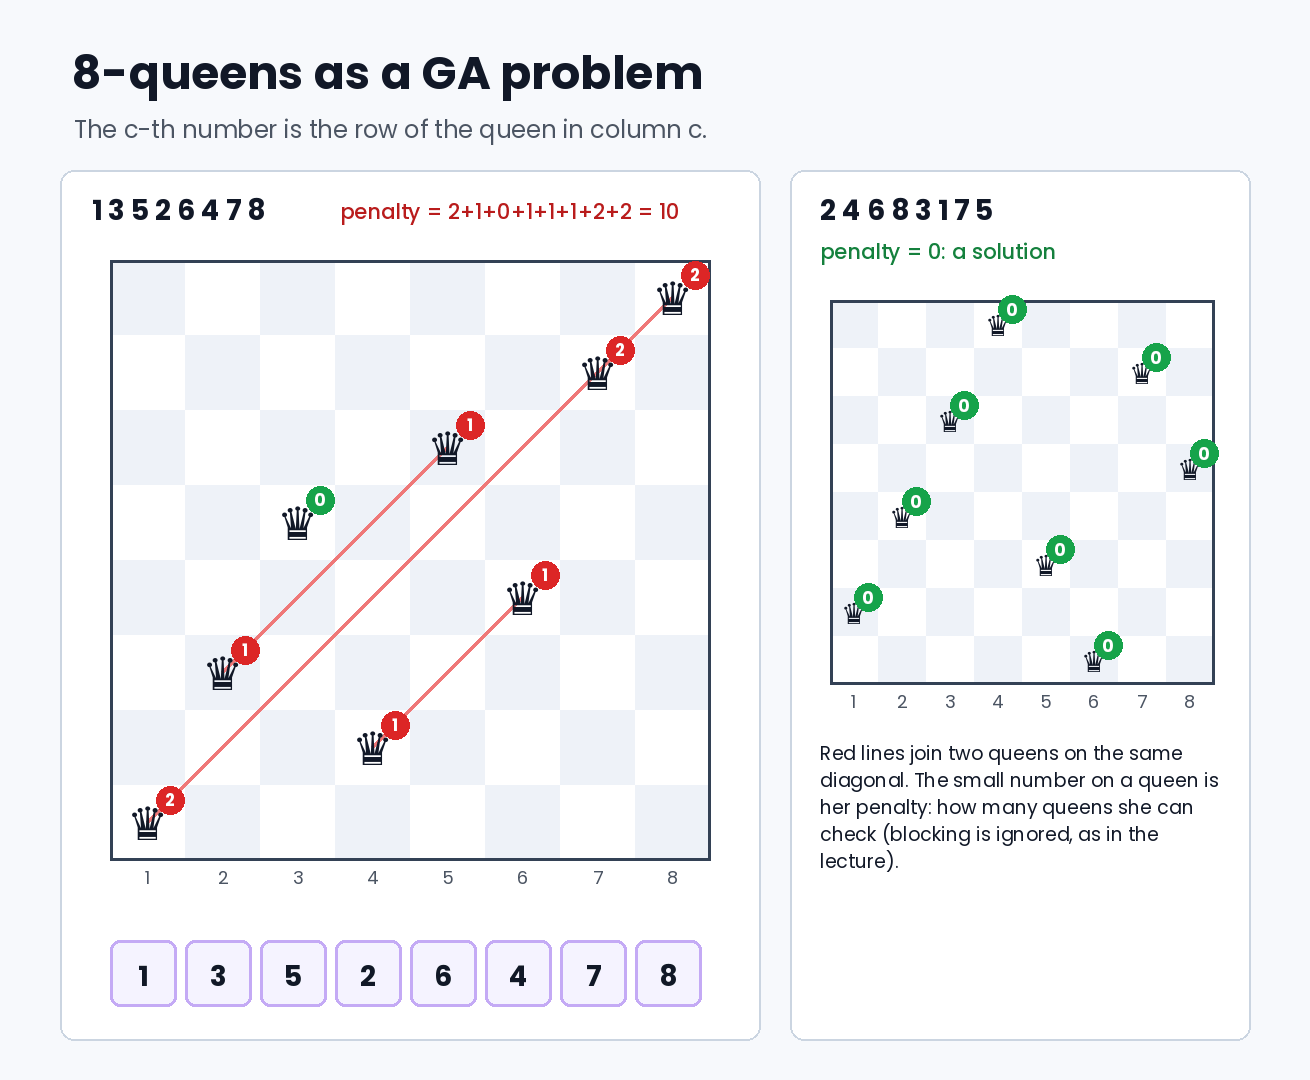


The lecture's choices for this problem:

| Part of the GA | Lecture 7 | In our code |
|---|---|---|
| Representation | permutations | `[1, 3, 5, 2, 6, 4, 7, 8]` |
| Recombination | cut-and-crossfill, probability 100% | `cut_and_crossfill`, `crossover_rate=1.0` |
| Mutation | swap, probability 80% | `swap_mutation`, `mutation_rate=0.8` |
| Parent selection | best 2 out of random 5 | `best_two_of_random_k` |
| Survivor selection | replace worst | a child replaces the worst member if it is at least as good |
| Population, offspring | 100, 2 | `pop_size=100`, two children per step |
| Initialisation, termination | random; solution or 10,000 fitness evaluations | random permutations, `max_evaluations=10_000` |

*"Note that this is only one possible set of choices of operators and parameters."*

### ✏️ Exercise 3: Penalty and cut-and-crossfill


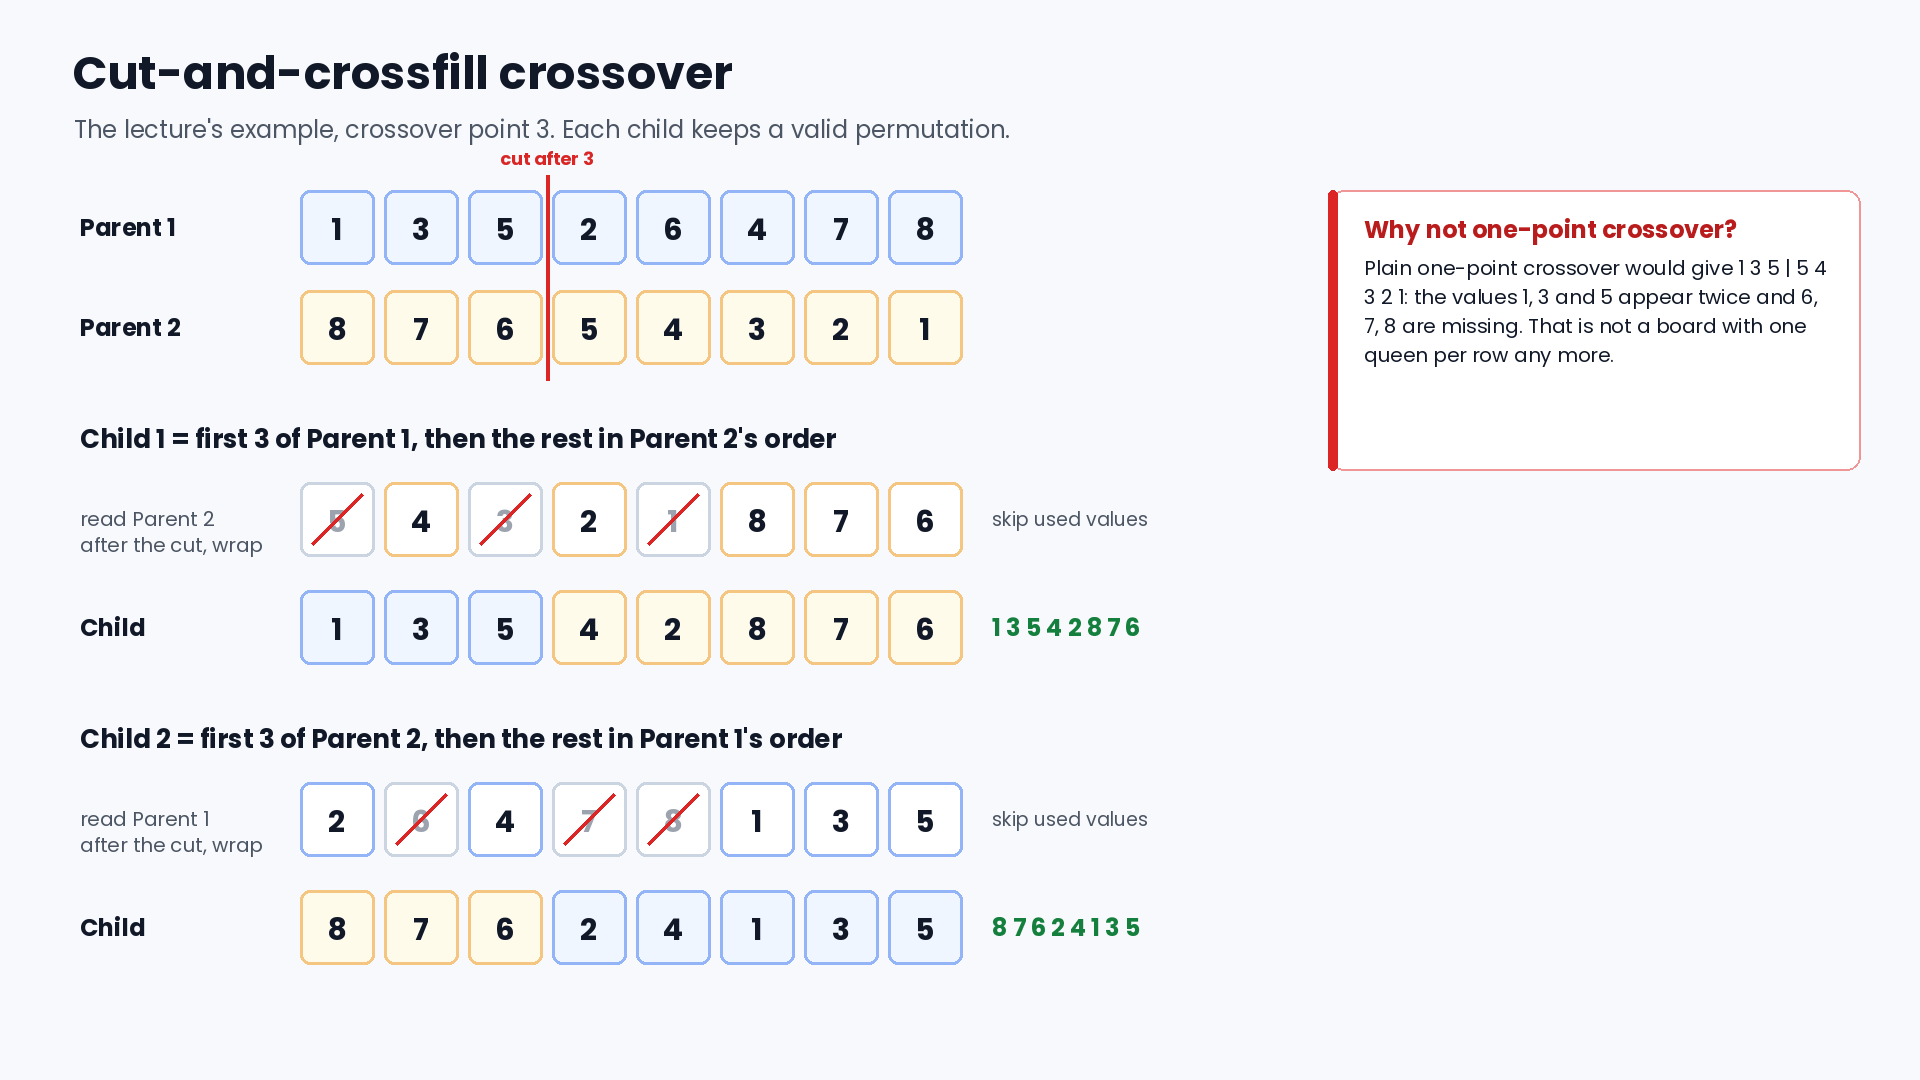


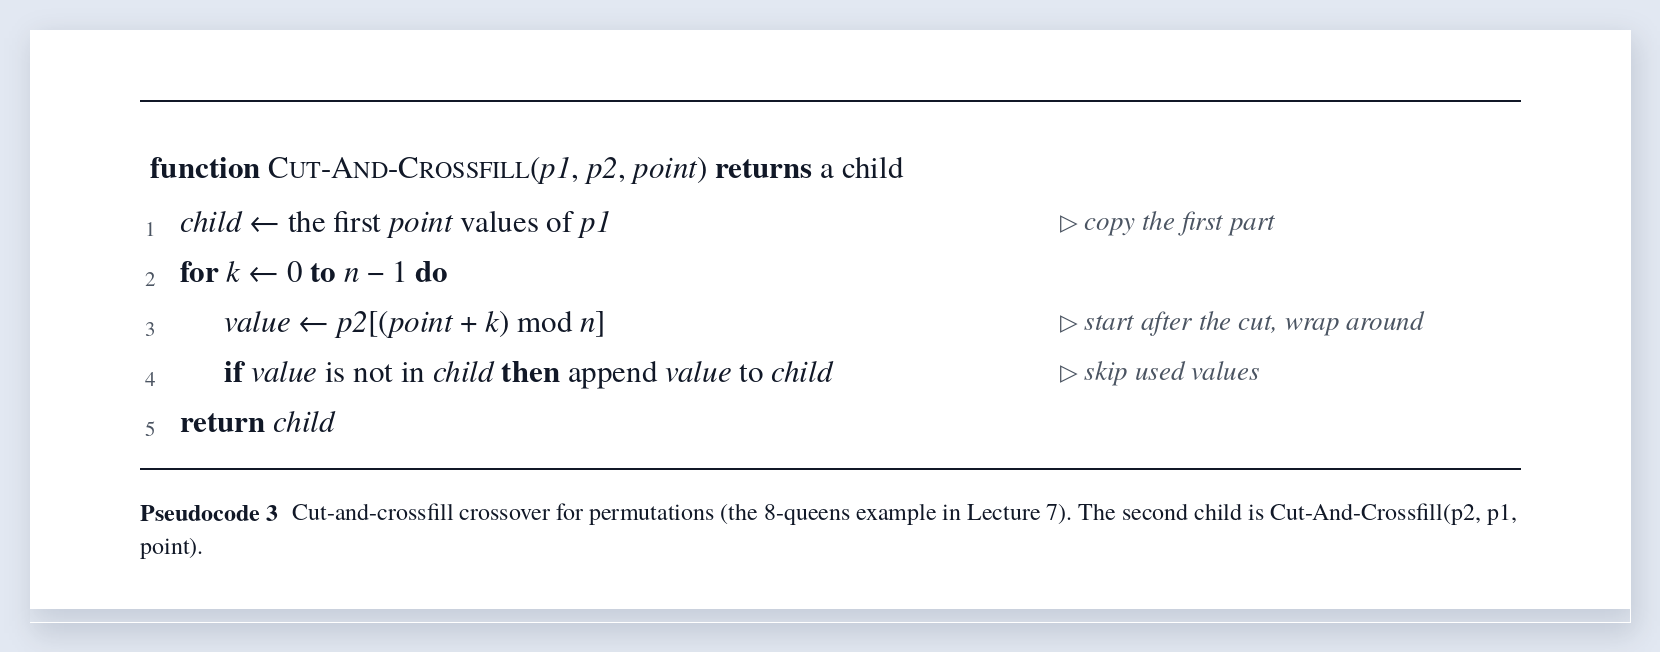


**(a) Predict.** On paper, write your answers in the first code cell:
1. the penalty of `[1, 3, 7, 2, 6, 4, 5, 8]` (the lecture's mutation example). Count the pairs of queens on a common diagonal.
2. the child `cut_and_crossfill([1, 3, 5, 2, 6, 4, 7, 8], [8, 7, 6, 5, 4, 3, 2, 1], 5)`.

**(b) Trace.** Check your child in the first tab of the activity below: type the parents, set point = 5 and press **Next** for each value.

**(c) Code.** Complete `queens_penalty` and `cut_and_crossfill`.

**(d) Test.** Run the test cell.


In [ ]:
# (a) your predictions
my_penalty = None    # TODO: the penalty of [1, 3, 7, 2, 6, 4, 5, 8]
my_child = None      # TODO: the child for point 5, as a list


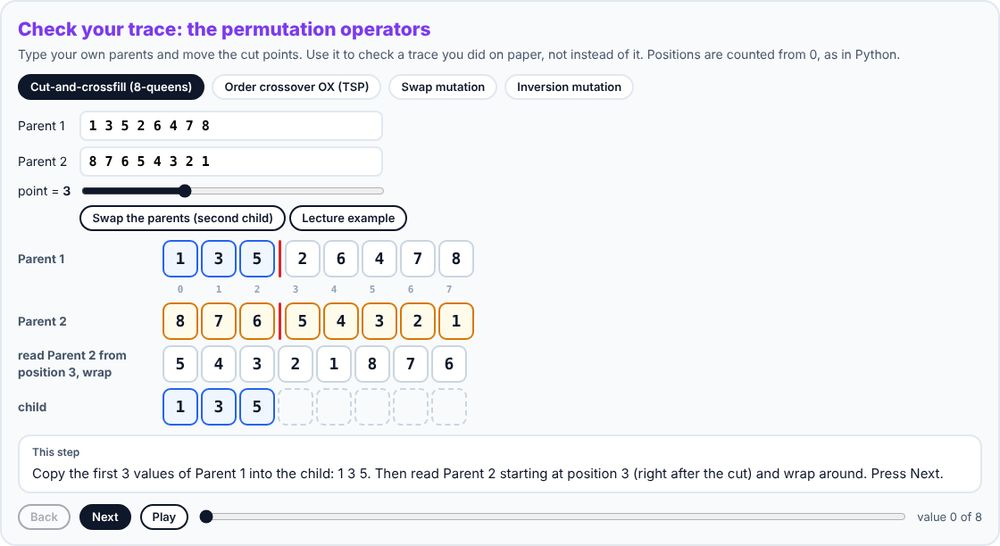

In [ ]:
show_activity("operators")

In [ ]:
def queens_penalty(board):
    """Lecture definition. board[c] = row of the queen in column c+1.

    Penalty of one queen = number of queens she can check.
    Penalty of the board = sum of the penalties of all queens.
    A permutation never has two queens in one row or column,
    so only diagonals can clash.
    """
    total = 0
    n = len(board)
    for i in range(n):
        for j in range(n):
            # TODO: if i != j and queens i and j are on the same diagonal, add 1 to total
            #       (same diagonal: the difference in rows equals the difference in columns)
            raise NotImplementedError("complete queens_penalty")
    return total


def cut_and_crossfill(p1, p2, point):
    """Lecture crossover for permutations (returns ONE child).

    1. Copy the first `point` values of p1.
    2. Fill the rest with values of p2 in the order they appear there,
       starting right after the crossover point and wrapping around,
       skipping values that are already in the child.
    """
    child = p1[:point]
    n = len(p2)
    for k in range(n):
        # TODO 1: value = the value of p2 at position (point + k), wrapping around with % n
        # TODO 2: if value is not in child yet, append it to child
        raise NotImplementedError("complete cut_and_crossfill")
    return child

In [ ]:
def queens_fitness(board):
    """Inverse penalty, to be maximised. 1.0 means a solution (penalty 0)."""
    return 1 / (1 + queens_penalty(board))


def swap_mutation(perm, i, j):
    """Swap the values at positions i and j."""
    out = perm[:]
    out[i], out[j] = out[j], out[i]
    return out


def best_two_of_random_k(population, fitnesses, k, rng):
    """Parent selection from the lecture: pick k at random, keep the best two."""
    picked = rng.sample(range(len(population)), k)
    picked.sort(key=lambda i: fitnesses[i], reverse=True)
    return population[picked[0]], population[picked[1]]

In [ ]:
check("penalty of the lecture's board", queens_penalty([1, 3, 5, 2, 6, 4, 7, 8]), 10)
check("penalty of a solution", queens_penalty([2, 4, 6, 8, 3, 1, 7, 5]), 0)
check("penalty when all queens share one diagonal", queens_penalty([1, 2, 3, 4, 5, 6, 7, 8]), 56)
check("your penalty", my_penalty, queens_penalty([1, 3, 7, 2, 6, 4, 5, 8]))
p1, p2 = [1, 3, 5, 2, 6, 4, 7, 8], [8, 7, 6, 5, 4, 3, 2, 1]
check("lecture: first child", cut_and_crossfill(p1, p2, 3), [1, 3, 5, 4, 2, 8, 7, 6])
check("lecture: second child", cut_and_crossfill(p2, p1, 3), [8, 7, 6, 2, 4, 1, 3, 5])
check("your child", my_child, cut_and_crossfill(p1, p2, 5))
check("lecture: swap mutation", swap_mutation(p1, 2, 6), [1, 3, 7, 2, 6, 4, 5, 8])
rng = random.Random(0)
valid = True
for _ in range(500):
    a, b = rng.sample(range(1, 9), 8), rng.sample(range(1, 9), 8)
    child = cut_and_crossfill(a, b, rng.randint(1, 7))
    valid = valid and sorted(child) == list(range(1, 9))
check("500 random children are all permutations", valid, True)

### 3.2 The lecture's GA for 8-queens

`queens_ga` follows the table above. It is a **steady-state** GA: instead of building a whole new generation, every step creates two children and inserts them into the population at once (*replace worst*). Like the lecture's termination rule, it counts **fitness evaluations**, including the 100 of the initial population, and stops as soon as a solution is found or the budget of 10,000 is used up.


In [ ]:
def queens_ga(pop_size=100, crossover_rate=1.0, mutation_rate=0.8, k=5,
              max_evaluations=10_000, seed=0, n=8):
    """The 8-queens GA from the lecture's summary table.

    Each step: select 2 parents (best 2 of random k), make 2 children with
    cut-and-crossfill, swap-mutate each child with probability mutation_rate,
    then each child replaces the worst member if it is at least as good.
    Stops when a solution is found or after max_evaluations fitness evaluations.
    """
    rng = random.Random(seed)
    population = [rng.sample(range(1, n + 1), n) for _ in range(pop_size)]
    fitnesses = [queens_fitness(b) for b in population]
    evaluations = pop_size
    history = [max(fitnesses)]
    while max(fitnesses) < 1 and evaluations < max_evaluations:
        p1, p2 = best_two_of_random_k(population, fitnesses, k, rng)
        if rng.random() < crossover_rate:
            point = rng.randint(1, n - 1)
            children = [cut_and_crossfill(p1, p2, point),
                        cut_and_crossfill(p2, p1, point)]
        else:
            children = [p1[:], p2[:]]
        for child in children:
            if max(fitnesses) == 1 or evaluations >= max_evaluations:
                break                              # solution found or budget used up
            if rng.random() < mutation_rate:
                i, j = rng.sample(range(n), 2)
                child = swap_mutation(child, i, j)
            fit = queens_fitness(child)
            evaluations += 1
            worst = min(range(pop_size), key=lambda m: fitnesses[m])
            if fit >= fitnesses[worst]:        # replace worst
                population[worst], fitnesses[worst] = child, fit
        history.append(max(fitnesses))
    best = max(range(pop_size), key=lambda m: fitnesses[m])
    return {"best": population[best], "penalty": queens_penalty(population[best]),
            "evaluations": evaluations, "history": history,
            "solved": fitnesses[best] == 1}


def show_board(board):
    """Print the board with the top row first (Q = queen)."""
    n = len(board)
    for row in range(n, 0, -1):
        print(" ".join("Q" if board[col] == row else "." for col in range(n)))


result = queens_ga(seed=0)
print("solved:", result["solved"], "| board:", result["best"], "| penalty:", result["penalty"])
print("fitness evaluations:", result["evaluations"], "of the 10,000 allowed")
show_board(result["best"])

One run is one random experiment, so the next cell repeats it with 50 seeds.

**Question (predict before you run):** with `mutation_rate=0`, only crossover changes the population. Will every run still find a solution?


In [ ]:
def queens_summary(**settings):
    runs = [queens_ga(seed=s, **settings) for s in range(50)]
    solved = [r["evaluations"] for r in runs if r["solved"]]
    print(f"{settings or 'lecture settings'}: solved {len(solved)}/50,"
          f" median evaluations of the solved runs {sorted(solved)[len(solved) // 2]}")

queens_summary()
queens_summary(mutation_rate=0)

---
## 4. Designing a GA for a new problem

> **Key idea.** The loop stays the same. For a new problem you design the representation, the fitness and the operators, and then tune and measure.

Lecture 7: *"Solution is only as good as the evaluation function; choosing a good one is often the hardest part"*, and *"similar-encoded solutions should have a similar fitness"*.

| A solution is… | Representation | Crossover | Mutation |
|---|---|---|---|
| a yes/no choice for each item | bit string | one-point, two-point | bit flip |
| an order of items, each used once | permutation | cut-and-crossfill, OX | swap, inversion |
| one of k values for each item | list of integers | one-point, two-point | set one gene to a random value |

1. **Representation:** choose the most natural encoding, preferably one in which many constraints hold automatically.
2. **Fitness:** bigger must mean better. Constraints that the representation cannot guarantee become a **penalty**, as in 8-queens. Check by hand that a better solution really receives a higher fitness.
3. **Operators:** they must always produce valid individuals. Test them as in Exercise 3: known examples plus many random inputs.
4. **Selection and survivors:** tournament selection and elitism are good defaults.
5. **Measure:** a GA is random, so compare settings over several seeds with the same number of fitness evaluations, and compare the GA with a simple baseline such as hill climbing.

**GA and hill climbing.** The two methods complement each other. Hill climbing improves one solution quickly but stops at a local optimum; a GA explores with a whole population but can be slow to make the final small improvements. A **memetic algorithm** combines them: each child is improved by a short local search, such as the hill climbing of Lab 5, before it enters the population. Whether this helps depends on the problem and on how many fitness evaluations the local search consumes, so it has to be measured. Designing and testing such a combination is part of the projects that ask for it.

### Summary

| | MAXONE | 8-queens | TSP (Additional Practice A) |
|---|---|---|---|
| Chromosome | bit string | permutation (row of the queen in each column) | permutation (order of the cities) |
| Fitness | number of 1s | 1 / (1 + penalty) | 1 / tour length |
| Parent selection | roulette wheel | best 2 of random 5 | tournament of 3 |
| Crossover | one-point | cut-and-crossfill | order crossover (OX) |
| Mutation | bit flip | swap | inversion |
| Survivors | generational + elitism | replace worst (steady-state) | generational + elitism |
| Stopping | target fitness | solution or 10,000 evaluations | number of generations |


---
# Additional Practice

The tutorial ends with Section 4. The Additional Practice continues after the lab: **A** applies your GA to the travelling salesman problem (Exercise 4), **B** to **D** use it to study the parameters of a GA, and **E** evolves a sentence.


---
## A: The travelling salesman problem

> **Key idea.** The same GA solves a different problem when we change three things: the **representation**, the **fitness** and the **operators**.

*"The travelling salesman must visit every city in his territory exactly once and then return to the starting point; given the cost of travel between all cities, how should he plan his itinerary for minimum total cost of the entire tour?"* A chromosome is the **order** in which the cities are visited.


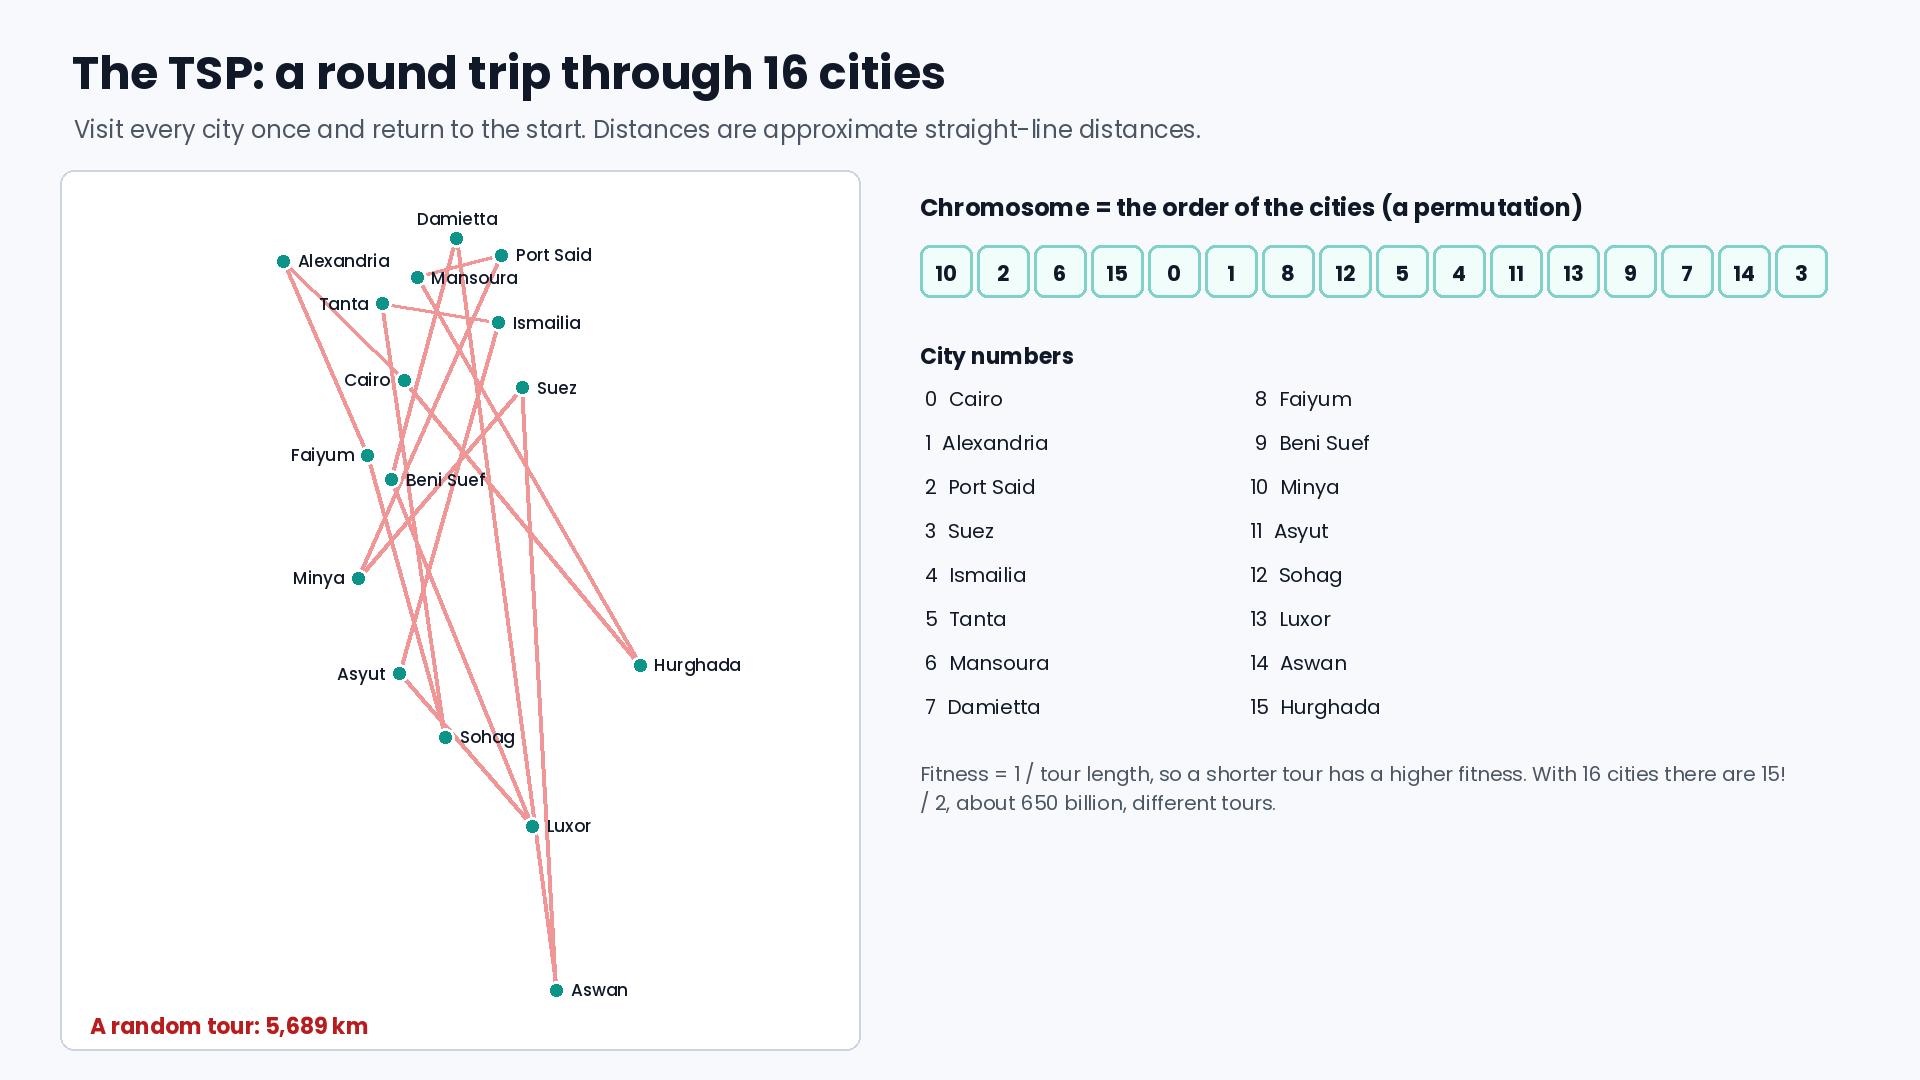


In [ ]:
CITIES = {                          # (longitude, latitude), approximate
    "Cairo": (31.24, 30.04), "Alexandria": (29.92, 31.20),
    "Port Said": (32.30, 31.26), "Suez": (32.53, 29.97),
    "Ismailia": (32.27, 30.60), "Tanta": (31.00, 30.79),
    "Mansoura": (31.38, 31.04), "Damietta": (31.81, 31.42),
    "Faiyum": (30.84, 29.31), "Beni Suef": (31.10, 29.07),
    "Minya": (30.74, 28.11), "Asyut": (31.18, 27.18),
    "Sohag": (31.69, 26.56), "Luxor": (32.64, 25.69),
    "Aswan": (32.90, 24.09), "Hurghada": (33.81, 27.26),
}
CITY_NAMES = list(CITIES)


def distance_km(a, b):
    """Approximate straight-line distance in km between two cities."""
    (lon1, lat1), (lon2, lat2) = CITIES[a], CITIES[b]
    mean_lat = math.radians((lat1 + lat2) / 2)
    dx = (lon2 - lon1) * 111.32 * math.cos(mean_lat)
    dy = (lat2 - lat1) * 110.57
    return math.hypot(dx, dy)


DIST = [[distance_km(a, b) for b in CITY_NAMES] for a in CITY_NAMES]


def tour_length(tour):
    """Total length of the closed tour (back to the start)."""
    return sum(DIST[tour[i]][tour[(i + 1) % len(tour)]] for i in range(len(tour)))


def random_tour(rng):
    """A random order of all the cities."""
    return rng.sample(range(len(CITY_NAMES)), len(CITY_NAMES))


print(round(DIST[0][14]), "km from Cairo to Aswan (straight line)")
tour = random_tour(random.Random(7))
print("a random tour:", tour, "->", round(tour_length(tour)), "km")

The coordinates are rounded and `distance_km` uses a flat-map approximation; for these cities it is within 1% of the great-circle distance. Road distances are longer, so the tour lengths are straight-line lengths, not driving distances.

For a tour, which cities are **next to each other** matters, not where the list starts. The lecture therefore uses **order crossover (OX)**: the child keeps a block of one parent's tour in place and takes the remaining cities in the order of the other parent. The mutation is **inversion**: reverse the cities between two cut points, for example `[1, 2, 3, 4, 5, 6, 7, 8, 9]` with cut points 2 and 7 becomes `[1, 2, 7, 6, 5, 4, 3, 8, 9]`. `order_crossover` is given.


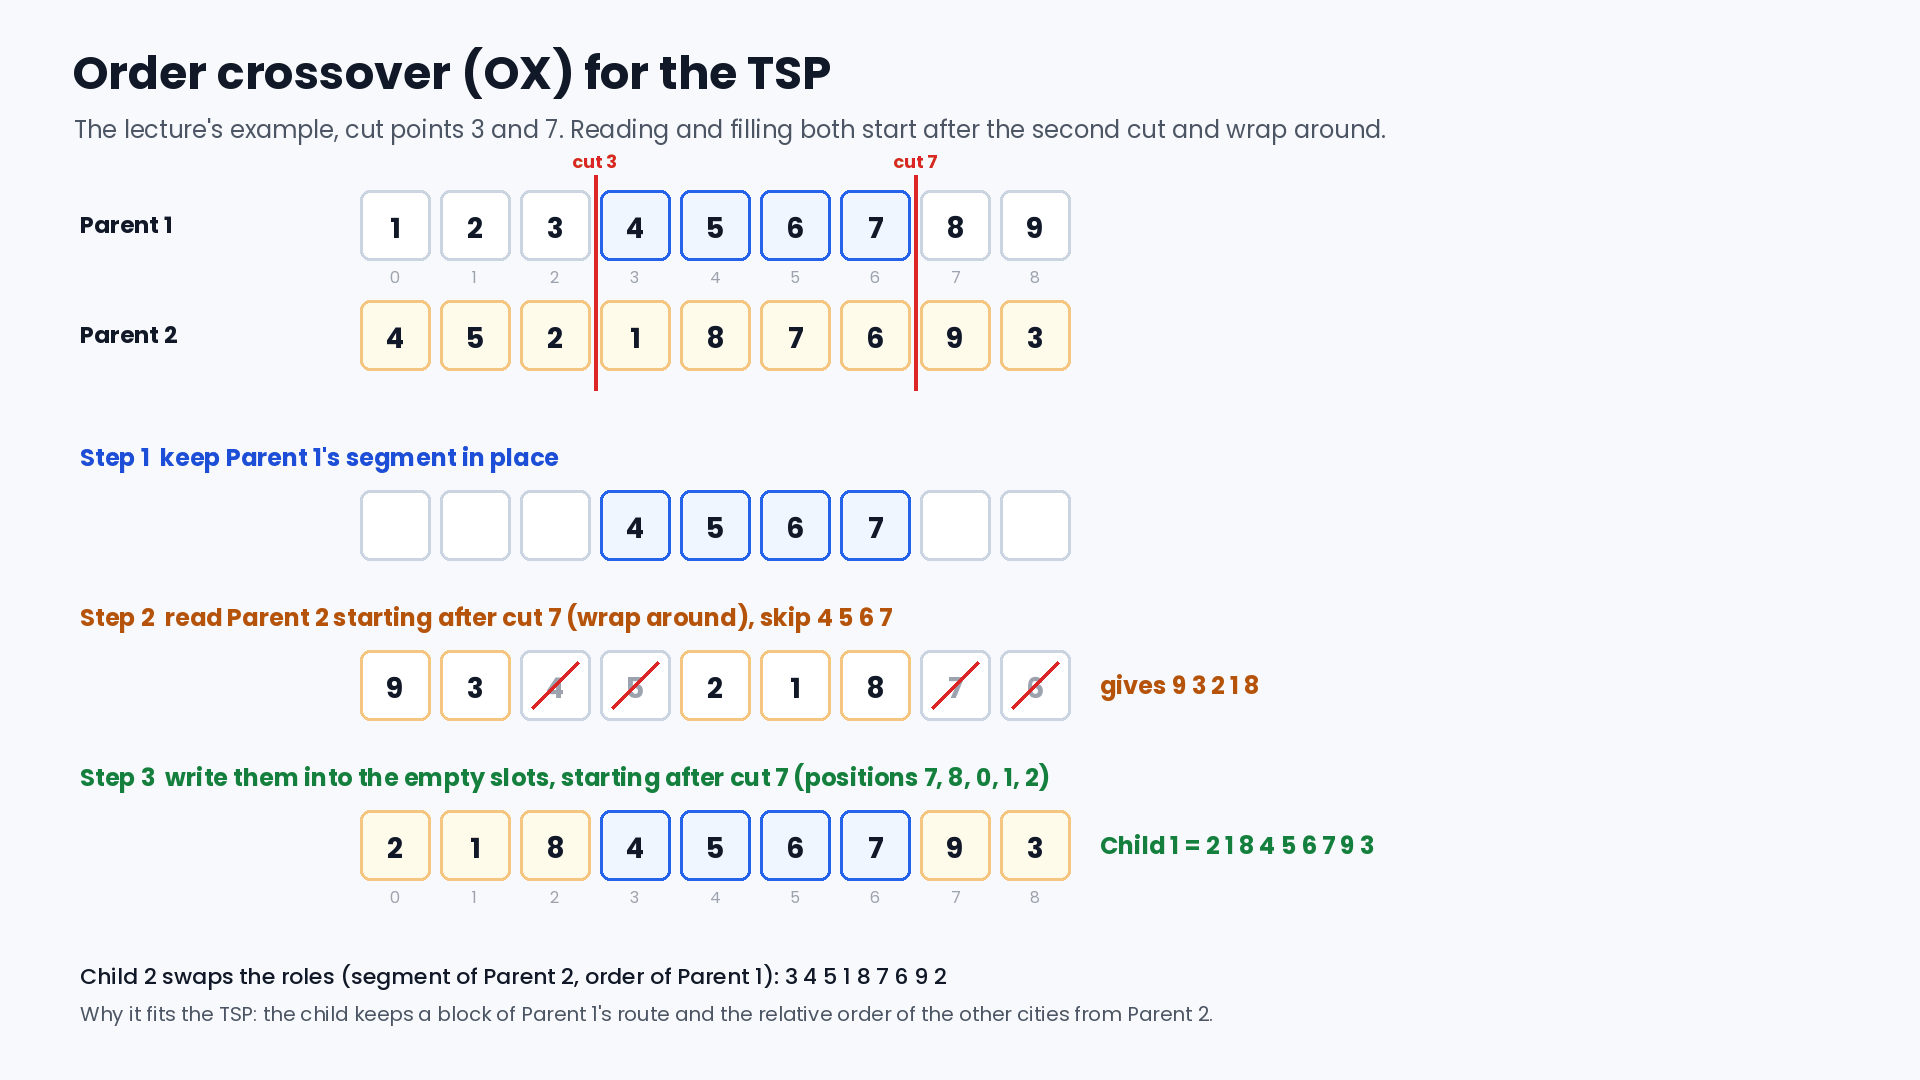


In [ ]:
def order_crossover(p1, p2, cut1, cut2):
    """Order crossover (OX), lecture version (returns ONE child).

    1. Copy p1[cut1:cut2] into the same positions of the child.
    2. Starting after the second cut point (wrapping around), read p2 and
       write the values not yet used into the empty positions, also starting
       after the second cut point and wrapping around.
    """
    n = len(p1)
    child = [None] * n
    child[cut1:cut2] = p1[cut1:cut2]
    used = set(p1[cut1:cut2])
    pos = cut2 % n
    for k in range(n):
        value = p2[(cut2 + k) % n]
        if value not in used:
            child[pos] = value
            used.add(value)
            pos = (pos + 1) % n
    return child

### ✏️ Exercise 4: The TSP fitness and inversion mutation

**(a) Predict.** With `p1 = [1, 2, 3, 4, 5, 6, 7, 8, 9]` and `p2 = [4, 5, 2, 1, 8, 7, 6, 9, 3]`, what are `order_crossover(p1, p2, 2, 5)` and `inversion_mutation(p1, 0, 4)`? Check both in the second and fourth tabs of the operator activity in Section 3.

**(b) Code.** Complete `tsp_fitness` (the inverse of the tour length) and `inversion_mutation`.

**(c) Test.** Run the test cell.


In [ ]:
# (a) your predictions
my_ox_child = None     # TODO: order_crossover(p1, p2, 2, 5) as a list
my_inverted = None     # TODO: inversion_mutation(p1, 0, 4) as a list

In [ ]:
def tsp_fitness(tour):
    """Inverse cost: shorter tour -> higher fitness."""
    # TODO: return the inverse of the tour length
    raise NotImplementedError("complete tsp_fitness")


def inversion_mutation(tour, cut1, cut2):
    """Reverse the part of the tour between the two cut points."""
    # TODO: return a new list: tour[:cut1], then tour[cut1:cut2] reversed, then tour[cut2:]
    raise NotImplementedError("complete inversion_mutation")

In [ ]:
p1, p2 = [1, 2, 3, 4, 5, 6, 7, 8, 9], [4, 5, 2, 1, 8, 7, 6, 9, 3]
check("lecture: OX children", (order_crossover(p1, p2, 3, 7), order_crossover(p2, p1, 3, 7)),
      ([2, 1, 8, 4, 5, 6, 7, 9, 3], [3, 4, 5, 1, 8, 7, 6, 9, 2]))
check("your OX child", my_ox_child, order_crossover(p1, p2, 2, 5))
check("lecture: inversion", inversion_mutation(p1, 2, 7), [1, 2, 7, 6, 5, 4, 3, 8, 9])
check("your inversion", my_inverted, inversion_mutation(p1, 0, 4))
check("inversion does not change its input", p1, [1, 2, 3, 4, 5, 6, 7, 8, 9])
tour = random_tour(random.Random(7))
check("fitness of a tour of 5,689 km", round(1 / tsp_fitness(tour)), 5689)
check("a shorter tour has a higher fitness", tsp_fitness([0, 1, 5, 6, 7, 2, 4, 3, 15, 14, 13, 12, 11, 10, 9, 8]) > tsp_fitness(tour), True)
rng = random.Random(0)
valid = True
for _ in range(500):
    a = random_tour(rng)
    c1, c2 = sorted(rng.sample(range(17), 2))
    valid = valid and sorted(inversion_mutation(a, c1, c2)) == list(range(16))
check("500 random inversions are valid tours", valid, True)

### Run the GA on the TSP

Your `genetic_algorithm` from Exercise 2 runs unchanged; only the problem functions are new. We use **tournament selection** with 3 members, OX with probability 0.9, inversion with probability 0.3 per child, and elitism.

Roulette selection is a poor choice here. Its probabilities are proportional to 1/length, and the lengths of tours in a random population are of the same order (most between about 3,800 and 6,400 km). In a random population of 100, the shortest tour is therefore picked only about 1.4 times as often as an average tour, and the difference shrinks further as the population improves. A tournament depends only on which tour is shorter, not on by how much.


In [ ]:
def tournament_select(population, fitnesses, rng, size=2):
    """Pick `size` members at random; the fittest one wins."""
    picked = rng.sample(range(len(population)), size)
    return population[max(picked, key=lambda i: fitnesses[i])]


def tsp_select(population, fitnesses, rng):
    """Tournament selection with 3 members (a little more pressure than 2)."""
    return tournament_select(population, fitnesses, rng, size=3)


def tsp_crossover(p1, p2, rng):
    """OX with two random cut points; returns two children."""
    n = len(p1)
    cut1, cut2 = sorted(rng.sample(range(n + 1), 2))
    return order_crossover(p1, p2, cut1, cut2), order_crossover(p2, p1, cut1, cut2)


def tsp_mutate(tour, rng, rate=0.3):
    """With probability `rate`, inversion between two random cut points."""
    if rng.random() >= rate:
        return tour
    n = len(tour)
    cut1, cut2 = sorted(rng.sample(range(n + 1), 2))
    return inversion_mutation(tour, cut1, cut2)


OPTIMUM = 2029.6     # km: the shortest tour for these distances

result = genetic_algorithm(tsp_fitness, random_tour, tsp_select, tsp_crossover, tsp_mutate,
                           pop_size=100, crossover_rate=0.9, elitism=1, max_generations=150, seed=1)
best = result["best"]
print("best tour:", round(tour_length(best)), "km after", result["generations"], "generations")
print(" -> ".join(CITY_NAMES[c] for c in best + best[:1]))

plt.figure(figsize=(7, 3))
plt.plot([1 / f for f in result["history"]], label="best tour")
plt.axhline(OPTIMUM, color="green", linestyle="--", label="shortest possible")
plt.xlabel("generation"); plt.ylabel("km"); plt.legend(); plt.show()

The shortest tour, 2,030 km, was computed with an exact dynamic-programming method (Held-Karp). It is feasible for 16 cities but its running time grows exponentially with the number of cities, which is why heuristic methods such as GAs are used for large instances. Here it only serves to check the GA: this run finds the shortest tour.

The activity replays three runs with fixed seeds: the 8-queens run from Section 3.2, this TSP run, and the same TSP run with roulette selection and no elitism. Compare the best-tour curves of the last two tabs. Each tab is **one** run; Additional Practice B compares the selection methods over several seeds.



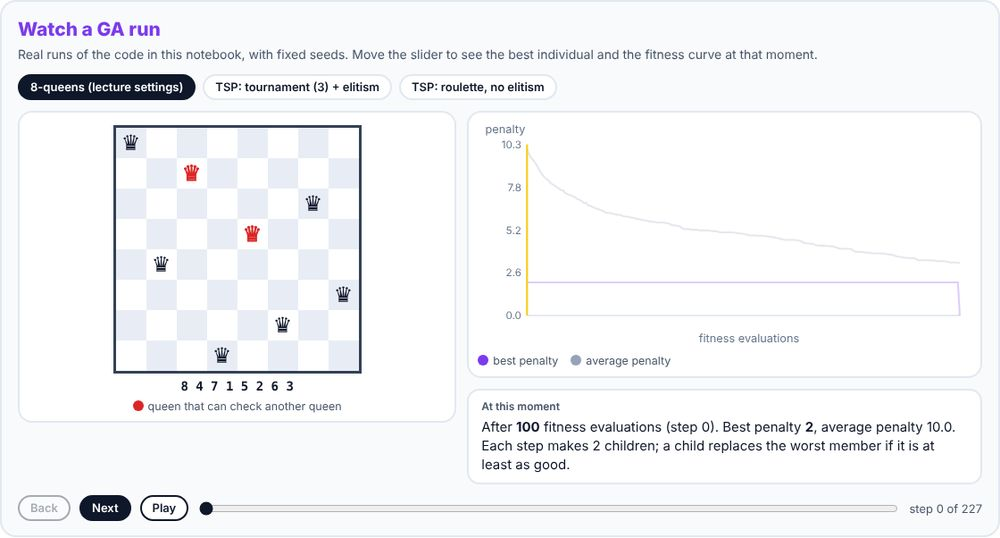

In [ ]:
show_activity("evolution", "evolution")

---
B to D use the TSP from A and the `genetic_algorithm` from Exercise 2. A GA is random, so every comparison runs each setting with the **same 10 seeds** and reports the average distance from the shortest tour and the number of runs that found it. Ten runs are enough to see large differences; small differences can still be due to chance.


In [ ]:
def tsp_trials(select=tsp_select, mutation_rate=0.3, seeds=range(10), **settings):
    """Run the TSP GA once per seed. Returns the average gap to the shortest tour (%) and the hits."""
    base = dict(pop_size=100, crossover_rate=0.9, elitism=1, max_generations=150)
    base.update(settings)
    mutate = lambda tour, rng: tsp_mutate(tour, rng, mutation_rate)
    gaps = []
    for s in seeds:
        r = genetic_algorithm(tsp_fitness, random_tour, select, tsp_crossover, mutate, seed=s, **base)
        gaps.append(max(0.0, 100 * (tour_length(r["best"]) - OPTIMUM) / OPTIMUM))
    return sum(gaps) / len(gaps), sum(g < 0.01 for g in gaps)

---
## B: Selection pressure

**Selection pressure** is how strongly fitter individuals are preferred. Too little and the search is almost random; too much and the population converges too fast.

**(a)** Predict the order of these set-ups, then run the cell: roulette without elitism, roulette with elitism, tournament of 2 with elitism, tournament of 3 with elitism.


In [ ]:
def tournament_of_2(population, fitnesses, rng):
    return tournament_select(population, fitnesses, rng, size=2)

setups = {"roulette, no elitism": dict(select=spin_roulette, elitism=0),
          "roulette + elitism": dict(select=spin_roulette),
          "tournament of 2 + elitism": dict(select=tournament_of_2),
          "tournament of 3 + elitism": dict(select=tsp_select)}
for name, settings in setups.items():
    gap, hits = tsp_trials(**settings)
    print(f"{name:27s} {gap:5.1f}% longer than the shortest on average | shortest found in {hits}/10 runs")

**(b)** Lecture 7, *selection according to ranking*: the k-th fittest member is selected with probability P(k) = (1/k) / D, where D = 1 + 1/2 + … + 1/n. Complete `rank_select`; the walk is the walk of `roulette_select` with the weights 1/k in place of the fitnesses. Then compare it with the set-ups above.


In [ ]:
def rank_select(population, fitnesses, rng):
    """Selection by ranking: the k-th best is chosen with P = (1/k) / D."""
    order = sorted(range(len(population)), key=lambda i: fitnesses[i], reverse=True)
    weights = [1 / k for k in range(1, len(order) + 1)]
    D = sum(weights)
    r = rng.uniform(0, D)
    running = 0
    for w, i in zip(weights, order):
        # TODO: add w to running; if running is now greater than r, return population[i]
        raise NotImplementedError("complete rank_select")
    return population[order[-1]]

In [ ]:
rng = random.Random(2)
picks = [rank_select(maxone_names, [7, 5, 7, 4, 8, 3], rng) for _ in range(24500)]
D = sum(1 / k for k in range(1, 7))
check("the best (s5) is picked with probability 1/D", abs(picks.count("s5") / 24500 - 1 / D) < 0.01, True)
check("the worst (s6) is picked with probability (1/6)/D", abs(picks.count("s6") / 24500 - (1 / 6) / D) < 0.01, True)
gap, hits = tsp_trials(select=rank_select)
print(f"rank selection + elitism: {gap:.1f}% longer than the shortest on average | shortest found in {hits}/10 runs")

---
## C: Exploration and exploitation

Lecture 7: *"Exploration (through mutation) versus exploitation (through crossover)"*. Predict how the results change with the probability of inversion mutation, then run the cell.


In [ ]:
for rate in [0, 0.1, 0.3, 0.6, 1.0]:
    gap, hits = tsp_trials(mutation_rate=rate)
    print(f"mutation probability {rate:3}: {gap:4.1f}% longer than the shortest on average | shortest found in {hits}/10 runs")

---
## D: Population size and stopping

A fair comparison of population sizes gives every setting the **same number of fitness evaluations**. A run uses `pop_size + generations × (pop_size − elitism)` evaluations (Exercise 2), so for a budget of 15,000 we choose the number of generations accordingly and print the evaluations actually used.


In [ ]:
BUDGET = 15000
for pop_size in [20, 50, 100, 300, 1000]:
    generations = (BUDGET - pop_size) // (pop_size - 1)
    used = pop_size + generations * (pop_size - 1)
    gap, hits = tsp_trials(pop_size=pop_size, max_generations=generations)
    print(f"population {pop_size:4} x {generations:3} generations ({used} evaluations): "
          f"{gap:4.1f}% on average | shortest found in {hits}/10 runs")

The lecture asks *"Are long runs beneficial?"* and answers *"it depends on how much you want the last bit of progress"*. The next run stops after **25 generations without improvement**, with at most 1000 generations.


In [ ]:
result = genetic_algorithm(tsp_fitness, random_tour, tsp_select, tsp_crossover, tsp_mutate,
                           pop_size=100, crossover_rate=0.9, elitism=1,
                           max_generations=1000, patience=25, seed=3)
km = [1 / f for f in result["history"]]
half = len(km) // 2
print("stopped after", result["generations"], "generations:", result["stop_reason"], "| best tour", round(km[-1]), "km")
print("improvement in the first half:", round(km[0] - km[half]), "km | in the second half:", round(km[half] - km[-1]), "km")

---
## E: Evolve a sentence

Each individual is a string of 25 characters and the target is `"GENETIC ALGORITHMS EVOLVE"`. Write the fitness: the number of positions where the string matches the target. A random guess matches the whole target with probability 1/27^25, about 1 in 6 × 10^35.


In [ ]:
TARGET = "GENETIC ALGORITHMS EVOLVE"
LETTERS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ "

def matching_chars(text):
    """Fitness: the number of positions where text has the same character as TARGET."""
    # TODO: compare text and TARGET position by position (zip) and count the matches
    raise NotImplementedError("complete matching_chars")

In [ ]:
def random_text(rng):
    return "".join(rng.choice(LETTERS) for _ in TARGET)

def text_mutate(text, rng):
    return "".join(rng.choice(LETTERS) if rng.random() < 1 / len(text) else c for c in text)

check("fitness of the target", matching_chars(TARGET), 25)
check("fitness of a string with 3 matches", matching_chars("GXNXTXXXXXXXXXXXXXXXXXXXX"), 3)
result = genetic_algorithm(matching_chars, random_text, tournament_select, maxone_crossover, text_mutate,
                           pop_size=100, crossover_rate=0.9, elitism=1,
                           max_generations=1000, target_fitness=len(TARGET), seed=0)
print(result["best"], "| generations:", result["generations"], "| evaluations:", result["evaluations"])

`maxone_crossover` works unchanged because one-point crossover only cuts and joins strings. Try other values of `pop_size` and of the mutation probability, and compare the number of evaluations over several seeds.
